# Red vs White — Wine Type Classification

UCI ships red and white wine as two separate CSVs with the same columns. Concatenating them gives a clean binary classification problem: predict the color from the chemistry. It's an easy problem — total sulfur dioxide alone gets you ridiculously far — but it makes a nice tight notebook.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import urllib.request

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(11)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/wine_type"); DATA_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
def get(url, name):
    p = DATA_DIR / name
    if not p.exists():
        urllib.request.urlretrieve(url, p)
    return pd.read_csv(p, sep=";")

red = get("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
          "winequality-red.csv")
white = get("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
            "winequality-white.csv")

red["is_red"] = 1
white["is_red"] = 0
df = pd.concat([red, white], ignore_index=True)
print(f"total: {len(df)}  red: {len(red)}  white: {len(white)}")


total: 6497  red: 1599  white: 4898


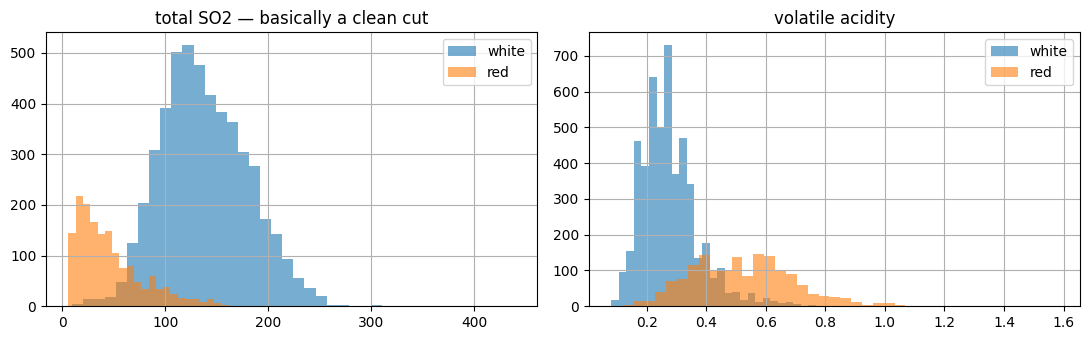

In [3]:
# the giveaway feature
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for lab, grp in df.groupby("is_red"):
    grp["total sulfur dioxide"].hist(bins=40, alpha=0.6, ax=ax[0], label=["white", "red"][lab])
ax[0].legend(); ax[0].set_title("total SO2 — basically a clean cut")
for lab, grp in df.groupby("is_red"):
    grp["volatile acidity"].hist(bins=40, alpha=0.6, ax=ax[1], label=["white", "red"][lab])
ax[1].legend(); ax[1].set_title("volatile acidity")
plt.tight_layout(); plt.savefig(ART / "eda.png", dpi=120); plt.show()


## modeling — LR with a scaler vs RF

In [4]:
features = [c for c in df.columns if c not in ["is_red", "quality"]]
X = df[features].values
y = df["is_red"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=11)

models = {
    "LR": Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "RF": RandomForestClassifier(n_estimators=200, random_state=11),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(f"{name}: test acc = {accuracy_score(y_test, pred):.4f}")


LR: test acc = 0.9938


RF: test acc = 0.9962


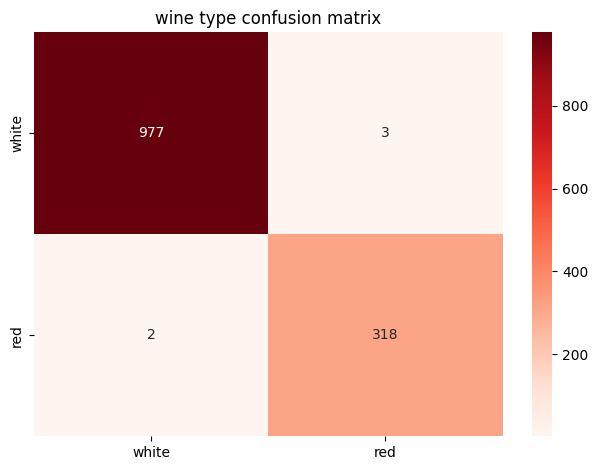

              precision    recall  f1-score   support

       white       1.00      1.00      1.00       980
         red       0.99      0.99      0.99       320

    accuracy                           1.00      1300
   macro avg       0.99      1.00      0.99      1300
weighted avg       1.00      1.00      1.00      1300



In [5]:
# confusion matrix on whichever one tied higher — RF normally wins by a hair
rf = models["RF"]
pred = rf.predict(X_test)
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds",
            xticklabels=["white", "red"], yticklabels=["white", "red"])
plt.title("wine type confusion matrix"); plt.tight_layout()
plt.savefig(ART / "cm.png", dpi=120); plt.show()
print(classification_report(y_test, pred, target_names=["white", "red"]))


## not much to say

This problem is too easy to be interesting on its own, but it's a useful warm-up for the harder quality-rating notebook next door. Test accuracy lands around 99% in my runs, which means almost every error is one of the genuinely ambiguous rows (a few whites with red-like sulfite levels). I left class imbalance alone — white outweighs red ~3:1 and it doesn't really matter at this accuracy.
